In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
Pandas: 3.0.5
Scikit-learn: 1.9.0


In [3]:
import os

folder_path = r"C:\Users\DELL\Documents\beijing+multi+site+air+quality+data\PRSA_Data_20130301-20170228"

files = [f for f in os.listdir(folder_path) if f.endswith(".csv")]

print("Number of CSV files:", len(files))
print(files)

Number of CSV files: 12
['PRSA_Data_Aotizhongxin_20130301-20170228.csv', 'PRSA_Data_Changping_20130301-20170228.csv', 'PRSA_Data_Dingling_20130301-20170228.csv', 'PRSA_Data_Dongsi_20130301-20170228.csv', 'PRSA_Data_Guanyuan_20130301-20170228.csv', 'PRSA_Data_Gucheng_20130301-20170228.csv', 'PRSA_Data_Huairou_20130301-20170228.csv', 'PRSA_Data_Nongzhanguan_20130301-20170228.csv', 'PRSA_Data_Shunyi_20130301-20170228.csv', 'PRSA_Data_Tiantan_20130301-20170228.csv', 'PRSA_Data_Wanliu_20130301-20170228.csv', 'PRSA_Data_Wanshouxigong_20130301-20170228.csv']


In [4]:
dataframes = []

for file in files:
    file_path = os.path.join(folder_path, file)
    df = pd.read_csv(file_path)
    dataframes.append(df)

air_quality = pd.concat(dataframes, ignore_index=True)

print("Dataset shape:", air_quality.shape)
print("\nColumn names:")
print(air_quality.columns.tolist())

print("\nFirst 5 rows:")
display(air_quality.head())

Dataset shape: (420768, 18)

Column names:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

First 5 rows:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [5]:
missing_values = air_quality.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", air_quality.isnull().sum().sum())

print("\nDuplicate rows:", air_quality.duplicated().sum())

Missing values in each column:
No             0
year           0
month          0
day            0
hour           0
PM2.5       8739
PM10        6449
SO2         9021
NO2        12116
CO         20701
O3         13277
TEMP         398
PRES         393
DEWP         403
RAIN         390
wd          1822
WSPM         318
station        0
dtype: int64

Total missing values: 74027

Duplicate rows: 0


In [6]:
missing_percent = (
    air_quality.isnull().sum() / len(air_quality) * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": air_quality.isnull().sum(),
    "Missing Percentage": missing_percent
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
PRES,393,0.09
RAIN,390,0.09


In [7]:
print("Total records:", len(air_quality))

print("Valid PM2.5 readings:", air_quality["PM2.5"].notna().sum())

print("Missing PM2.5 readings:", air_quality["PM2.5"].isna().sum())

print("\nPM2.5 statistics:")
display(air_quality["PM2.5"].describe())

Total records: 420768
Valid PM2.5 readings: 412029
Missing PM2.5 readings: 8739

PM2.5 statistics:


count    412029.000000
mean         79.793428
std          80.822391
min           2.000000
25%          20.000000
50%          55.000000
75%         111.000000
max         999.000000
Name: PM2.5, dtype: float64

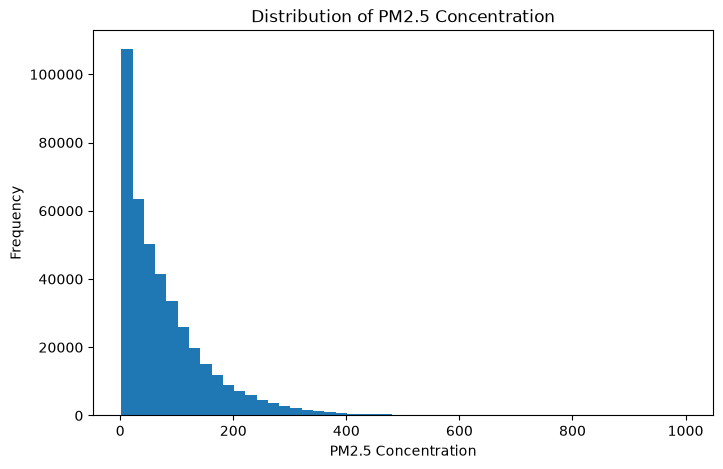

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(air_quality["PM2.5"].dropna(), bins=50)

plt.title("Distribution of PM2.5 Concentration")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Frequency")

plt.show()

station
Dongsi           86.194297
Wanshouxigong    85.024136
Nongzhanguan     84.838483
Gucheng          83.852089
Wanliu           83.374716
Guanyuan         82.933372
Aotizhongxin     82.773611
Tiantan          82.164911
Shunyi           79.491602
Changping        71.099743
Huairou          69.626367
Dingling         65.989497
Name: PM2.5, dtype: float64

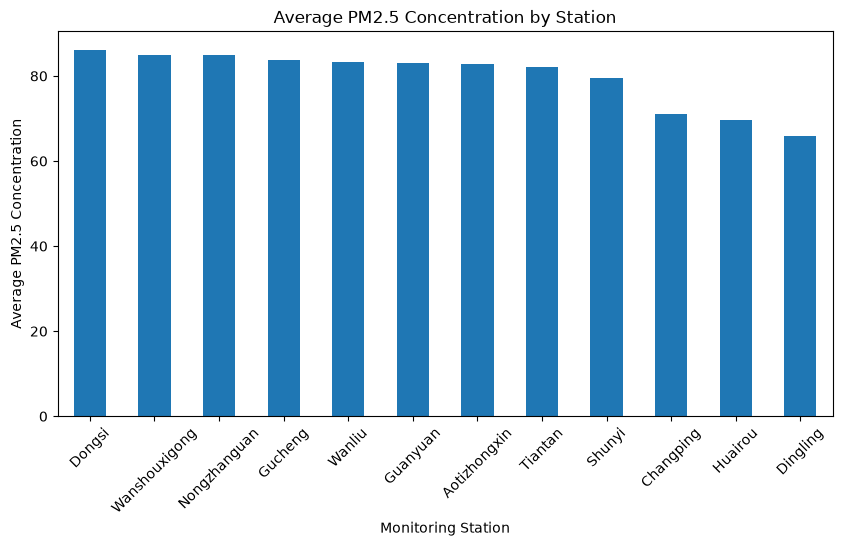

In [9]:
station_pollution = air_quality.groupby("station")["PM2.5"].mean()
station_pollution = station_pollution.sort_values(ascending=False)

display(station_pollution)

plt.figure(figsize=(10, 5))
station_pollution.plot(kind="bar")

plt.title("Average PM2.5 Concentration by Station")
plt.xlabel("Monitoring Station")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(rotation=45)

plt.show()

In [10]:
missing_summary = pd.DataFrame({
    "Missing Values": air_quality.isnull().sum(),
    "Missing Percentage": (
        air_quality.isnull().sum() / len(air_quality) * 100
    ).round(2)
})

display(missing_summary[missing_summary["Missing Values"] > 0])

,Missing Values,Missing Percentage
PM2.5,8739,2.08
PM10,6449,1.53
SO2,9021,2.14
NO2,12116,2.88
CO,20701,4.92
O3,13277,3.16
TEMP,398,0.09
PRES,393,0.09
DEWP,403,0.10
RAIN,390,0.09


In [11]:
cleaned_data = air_quality.copy()
cleaned_data = cleaned_data.dropna(subset=["PM2.5"])

print("Original dataset shape:", air_quality.shape)
print("After removing missing PM2.5:", cleaned_data.shape)
print("Remaining missing values:", cleaned_data.isnull().sum().sum())

Original dataset shape: (420768, 18)
After removing missing PM2.5: (412029, 18)
Remaining missing values: 37666


In [12]:
numerical_columns = cleaned_data.select_dtypes(include="number").columns

for col in numerical_columns:
    if col != "PM2.5":
        cleaned_data[col] = cleaned_data[col].fillna(
            cleaned_data[col].median()
        )

cleaned_data["wd"] = cleaned_data["wd"].fillna(
    cleaned_data["wd"].mode()[0]
)

print("Remaining missing values:", cleaned_data.isnull().sum().sum())
print("Cleaned dataset shape:", cleaned_data.shape)

Remaining missing values: 0
Cleaned dataset shape: (412029, 18)


In [13]:
cleaned_data["datetime"] = pd.to_datetime(
    cleaned_data[["year", "month", "day", "hour"]]
)

print("Date range:")
print("Start:", cleaned_data["datetime"].min())
print("End:", cleaned_data["datetime"].max())

print("\nFirst 5 date-time values:")
display(cleaned_data[["datetime", "station", "PM2.5"]].head())

Date range:
Start: 2013-03-01 00:00:00
End: 2017-02-28 23:00:00

First 5 date-time values:


,datetime,station,PM2.5
0,2013-03-01 00:00:00,Aotizhongxin,4.0
1,2013-03-01 01:00:00,Aotizhongxin,8.0
2,2013-03-01 02:00:00,Aotizhongxin,7.0
3,2013-03-01 03:00:00,Aotizhongxin,6.0
4,2013-03-01 04:00:00,Aotizhongxin,3.0


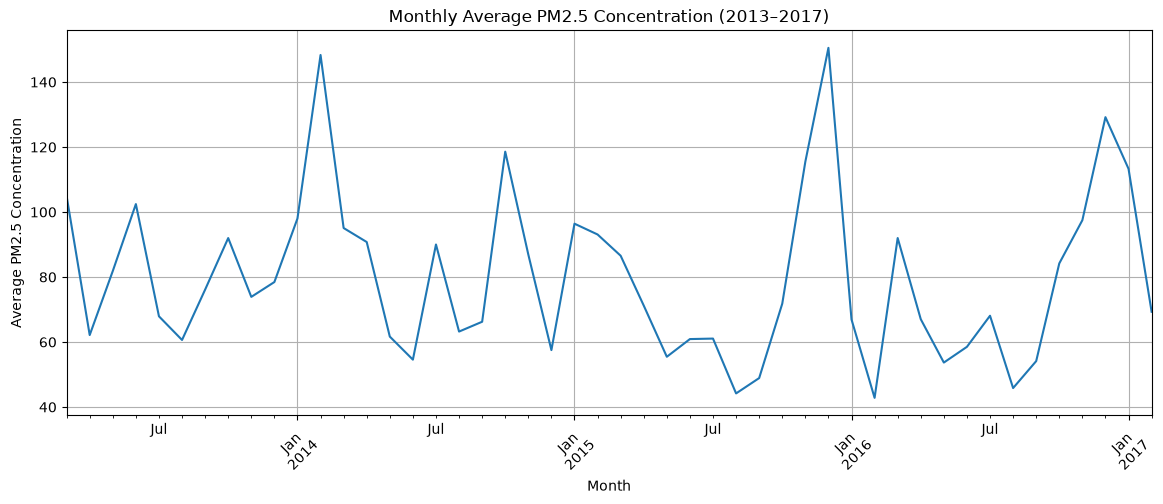

In [14]:
monthly_pollution = cleaned_data.groupby(
    cleaned_data["datetime"].dt.to_period("M")
)["PM2.5"].mean()

plt.figure(figsize=(14, 5))
monthly_pollution.plot()

plt.title("Monthly Average PM2.5 Concentration (2013–2017)")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

season
Spring    76.973508
Summer    64.674881
Autumn    82.332246
Winter    95.483630
Name: PM2.5, dtype: float64

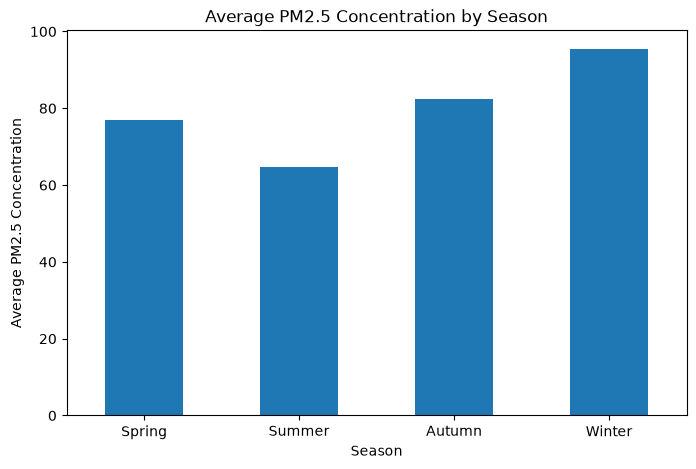

In [15]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

cleaned_data["season"] = cleaned_data["month"].apply(get_season)

seasonal_pollution = cleaned_data.groupby("season")["PM2.5"].mean()
seasonal_pollution = seasonal_pollution.reindex(
    ["Spring", "Summer", "Autumn", "Winter"]
)

display(seasonal_pollution)

plt.figure(figsize=(8, 5))
seasonal_pollution.plot(kind="bar")

plt.title("Average PM2.5 Concentration by Season")
plt.xlabel("Season")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(rotation=0)
plt.show()

In [16]:
features = [
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM",
    "wd",
    "station",
    "month",
    "hour"
]

target = "PM2.5"

X = cleaned_data[features].copy()
y = cleaned_data[target].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget preview:")
display(y.head())

Feature shape: (412029, 14)
Target shape: (412029,)

Features:
['PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'wd', 'station', 'month', 'hour']

Target preview:


0    4.0
1    8.0
2    7.0
3    6.0
4    3.0
Name: PM2.5, dtype: float64

In [17]:
X_encoded = pd.get_dummies(
    X,
    columns=["wd", "station"],
    dtype=int
)

print("Original feature shape:", X.shape)
print("Encoded feature shape:", X_encoded.shape)

print("\nFirst 5 rows of encoded data:")
display(X_encoded.head())

Original feature shape: (412029, 14)
Encoded feature shape: (412029, 40)

First 5 rows of encoded data:


,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,...,station_Dingling,station_Dongsi,station_Guanyuan,station_Gucheng,station_Huairou,station_Nongzhanguan,station_Shunyi,station_Tiantan,station_Wanliu,station_Wanshouxigong
0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,4.4,...,0,0,0,0,0,0,0,0,0,0
1,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,4.7,...,0,0,0,0,0,0,0,0,0,0
2,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,5.6,...,0,0,0,0,0,0,0,0,0,0
3,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,3.1,...,0,0,0,0,0,0,0,0,0,0
4,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,2.0,...,0,0,0,0,0,0,0,0,0,0


In [18]:
sorted_indices = cleaned_data.sort_values("datetime").index

unique_times = cleaned_data.loc[sorted_indices, "datetime"].drop_duplicates()
split_position = int(len(unique_times) * 0.8)
split_time = unique_times.iloc[split_position]

train_mask = cleaned_data.loc[X_encoded.index, "datetime"] < split_time

X_train = X_encoded.loc[train_mask]
X_test = X_encoded.loc[~train_mask]

y_train = y.loc[train_mask]
y_test = y.loc[~train_mask]

print("Split timestamp:", split_time)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training period:", cleaned_data.loc[X_train.index, "datetime"].min(), "to", cleaned_data.loc[X_train.index, "datetime"].max())
print("Testing period:", cleaned_data.loc[X_test.index, "datetime"].min(), "to", cleaned_data.loc[X_test.index, "datetime"].max())

Split timestamp: 2016-05-12 09:00:00
Training samples: 329478
Testing samples: 82551
Training period: 2013-03-01 00:00:00 to 2016-05-12 08:00:00
Testing period: 2016-05-12 09:00:00 to 2017-02-28 23:00:00


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

print("\nTraining data mean (first 5 features):")
print(X_train_scaled[:, :5].mean(axis=0).round(2))

print("\nTraining data standard deviation (first 5 features):")
print(X_train_scaled[:, :5].std(axis=0).round(2))

Scaled training data shape: (329478, 40)
Scaled testing data shape: (82551, 40)

Training data mean (first 5 features):
[-0. -0. -0.  0. -0.]

Training data standard deviation (first 5 features):
[1. 1. 1. 1. 1.]


In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

print("Multiple Linear Regression Results")
print("----------------------------------")
print("MAE:", round(lr_mae, 2))
print("RMSE:", round(lr_rmse, 2))
print("R2 Score:", round(lr_r2, 4))

Multiple Linear Regression Results
----------------------------------
MAE: 16.96
RMSE: 24.61
R2 Score: 0.9129


In [21]:
from sklearn.preprocessing import PolynomialFeatures

poly_features = [
    "PM10", "NO2", "CO", "TEMP", "DEWP", "WSPM", "month", "hour"
]

X_train_poly_base = X_train[poly_features]
X_test_poly_base = X_test[poly_features]

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_poly_base)
X_test_poly = poly.transform(X_test_poly_base)

print("Training shape:", X_train_poly.shape)
print("Testing shape:", X_test_poly.shape)

Training shape: (329478, 44)
Testing shape: (82551, 44)


In [22]:
poly_scaler = StandardScaler()

X_train_poly_scaled = poly_scaler.fit_transform(X_train_poly)
X_test_poly_scaled = poly_scaler.transform(X_test_poly)

poly_model = LinearRegression()
poly_model.fit(X_train_poly_scaled, y_train)

poly_predictions = poly_model.predict(X_test_poly_scaled)

poly_mae = mean_absolute_error(y_test, poly_predictions)
poly_rmse = np.sqrt(mean_squared_error(y_test, poly_predictions))
poly_r2 = r2_score(y_test, poly_predictions)

print("Polynomial Regression Results")
print("----------------------------------")
print("MAE:", round(poly_mae, 2))
print("RMSE:", round(poly_rmse, 2))
print("R2 Score:", round(poly_r2, 4))

Polynomial Regression Results
----------------------------------
MAE: 14.46
RMSE: 22.66
R2 Score: 0.9261


In [23]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=15,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_predictions))
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Regression Results")
print("----------------------------------")
print("MAE:", round(dt_mae, 2))
print("RMSE:", round(dt_rmse, 2))
print("R2 Score:", round(dt_r2, 4))

Decision Tree Regression Results
----------------------------------
MAE: 14.42
RMSE: 24.75
R2 Score: 0.9119


In [24]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Regression Results")
print("----------------------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

Random Forest Regression Results
----------------------------------
MAE: 12.37
RMSE: 20.15
R2 Score: 0.9416


In [25]:
results = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Polynomial Regression",
        "Decision Tree Regression",
        "Random Forest Regression"
    ],
    "MAE": [lr_mae, poly_mae, dt_mae, rf_mae],
    "RMSE": [lr_rmse, poly_rmse, dt_rmse, rf_rmse],
    "R2 Score": [lr_r2, poly_r2, dt_r2, rf_r2]
})

results = results.round(4)

results

,Model,MAE,RMSE,R2 Score
0,Multiple Linear Regression,16.9607,24.6055,0.9129
1,Polynomial Regression,14.4585,22.6610,0.9261
2,Decision Tree Regression,14.4175,24.7457,0.9119
3,Random Forest Regression,12.3678,20.1507,0.9416


In [26]:
print("PM2.5 Statistical Summary")
print("-------------------------")
print(cleaned_data["PM2.5"].describe())

print("\nPM2.5 Percentiles")
print("-------------------------")
print(cleaned_data["PM2.5"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

PM2.5 Statistical Summary
-------------------------
count    412029.000000
mean         79.793428
std          80.822391
min           2.000000
25%          20.000000
50%          55.000000
75%         111.000000
max         999.000000
Name: PM2.5, dtype: float64

PM2.5 Percentiles
-------------------------
0.25     20.0
0.50     55.0
0.75    111.0
0.90    185.0
0.95    242.0
0.99    370.0
Name: PM2.5, dtype: float64


In [27]:
Q1 = cleaned_data["PM2.5"].quantile(0.25)
Q3 = cleaned_data["PM2.5"].quantile(0.75)

IQR = Q3 - Q1

upper_threshold = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper Anomaly Threshold:", upper_threshold)

Q1: 20.0
Q3: 111.0
IQR: 91.0
Upper Anomaly Threshold: 247.5


In [28]:
cleaned_data["Pollution_Anomaly"] = (
    cleaned_data["PM2.5"] > upper_threshold
)

anomalies = cleaned_data[cleaned_data["Pollution_Anomaly"]]

total_records = len(cleaned_data)
anomaly_count = len(anomalies)
normal_count = total_records - anomaly_count

print("Pollution Anomaly Detection Results")
print("-----------------------------------")
print("Total Records:", total_records)
print("Normal Records:", normal_count)
print("Anomaly Records:", anomaly_count)
print("Anomaly Percentage:", round((anomaly_count / total_records) * 100, 2), "%")

Pollution Anomaly Detection Results
-----------------------------------
Total Records: 412029
Normal Records: 392887
Anomaly Records: 19142
Anomaly Percentage: 4.65 %


High-Pollution Anomalies by Station
-----------------------------------
station
Dongsi           1979
Nongzhanguan     1973
Wanshouxigong    1875
Wanliu           1723
Aotizhongxin     1717
Gucheng          1704
Guanyuan         1632
Tiantan          1631
Shunyi           1593
Changping        1152
Dingling         1142
Huairou          1021
dtype: int64


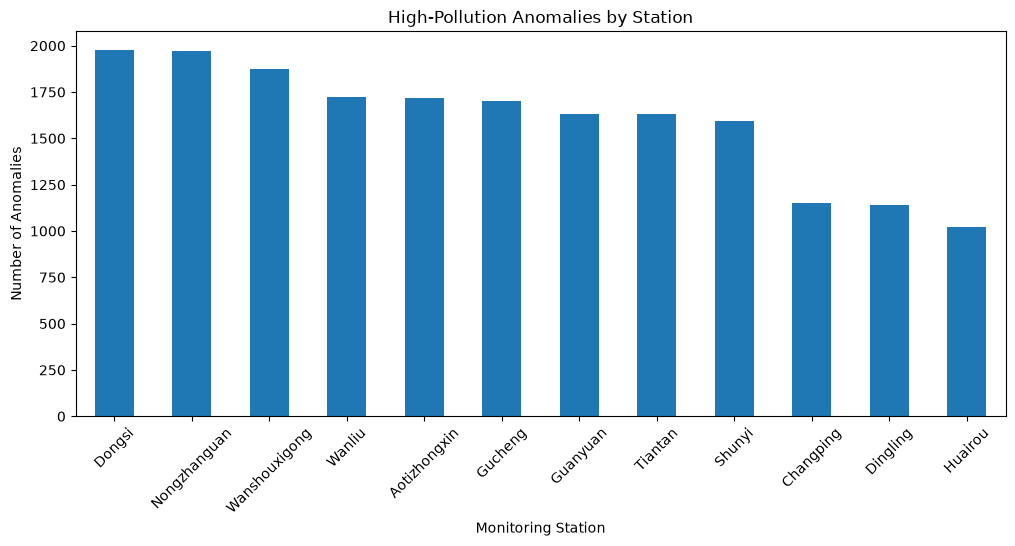

In [29]:
station_anomalies = (
    anomalies.groupby("station")
    .size()
    .sort_values(ascending=False)
)

print("High-Pollution Anomalies by Station")
print("-----------------------------------")
print(station_anomalies)

station_anomalies.plot(
    kind="bar",
    figsize=(12, 5),
    title="High-Pollution Anomalies by Station"
)

plt.xlabel("Monitoring Station")
plt.ylabel("Number of Anomalies")
plt.xticks(rotation=45)
plt.show()

High-Pollution Anomalies by Season
----------------------------------
season
Spring    3242
Summer     634
Autumn    5812
Winter    9454
dtype: int64


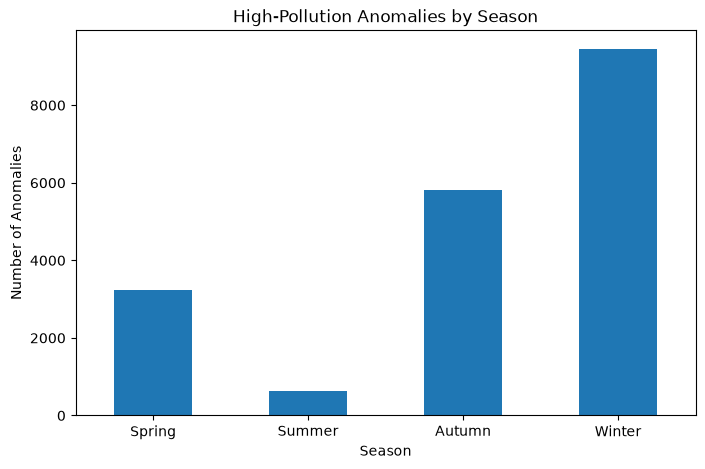

In [30]:
season_anomalies = (
    anomalies.groupby("season")
    .size()
    .reindex(["Spring", "Summer", "Autumn", "Winter"])
)

print("High-Pollution Anomalies by Season")
print("----------------------------------")
print(season_anomalies)

season_anomalies.plot(
    kind="bar",
    figsize=(8, 5),
    title="High-Pollution Anomalies by Season"
)

plt.xlabel("Season")
plt.ylabel("Number of Anomalies")
plt.xticks(rotation=0)
plt.show()

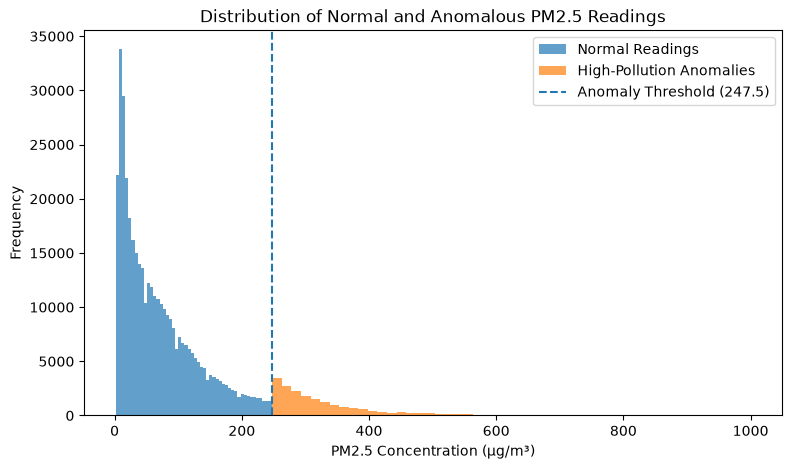

In [31]:
plt.figure(figsize=(9, 5))

plt.hist(
    cleaned_data.loc[~cleaned_data["Pollution_Anomaly"], "PM2.5"],
    bins=50,
    alpha=0.7,
    label="Normal Readings"
)

plt.hist(
    anomalies["PM2.5"],
    bins=50,
    alpha=0.7,
    label="High-Pollution Anomalies"
)

plt.axvline(
    upper_threshold,
    linestyle="--",
    label=f"Anomaly Threshold ({upper_threshold})"
)

plt.title("Distribution of Normal and Anomalous PM2.5 Readings")
plt.xlabel("PM2.5 Concentration (µg/m³)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [32]:
station_analysis = cleaned_data.groupby("station").agg(
    Total_Readings=("PM2.5", "count"),
    Anomaly_Count=("Pollution_Anomaly", "sum")
)

station_analysis["Anomaly_Percentage"] = (
    station_analysis["Anomaly_Count"] /
    station_analysis["Total_Readings"] * 100
)

station_analysis = station_analysis.sort_values(
    "Anomaly_Percentage", ascending=False
)

print(station_analysis.round(2))

               Total_Readings  Anomaly_Count  Anomaly_Percentage
station                                                         
Dongsi                  34314           1979                5.77
Nongzhanguan            34436           1973                5.73
Wanshouxigong           34368           1875                5.46
Aotizhongxin            34139           1717                5.03
Wanliu                  34682           1723                4.97
Gucheng                 34418           1704                4.95
Tiantan                 34387           1631                4.74
Guanyuan                34448           1632                4.74
Shunyi                  34151           1593                4.66
Changping               34290           1152                3.36
Dingling                34285           1142                3.33
Huairou                 34111           1021                2.99


In [33]:
season_analysis = cleaned_data.groupby("season").agg(
    Total_Readings=("PM2.5", "count"),
    Anomaly_Count=("Pollution_Anomaly", "sum")
)

season_analysis["Anomaly_Percentage"] = (
    season_analysis["Anomaly_Count"] /
    season_analysis["Total_Readings"] * 100
)

season_analysis = season_analysis.reindex(
    ["Spring", "Summer", "Autumn", "Winter"]
)

print(season_analysis.round(2))

        Total_Readings  Anomaly_Count  Anomaly_Percentage
season                                                   
Spring          103705           3242                3.13
Summer          103671            634                0.61
Autumn          102746           5812                5.66
Winter          101907           9454                9.28


Random Forest Feature Importance
--------------------------------
                  Feature  Importance
0                    PM10      0.8052
3                      CO      0.1083
7                    DEWP      0.0178
5                    TEMP      0.0148
1                     SO2      0.0108
10                  month      0.0106
2                     NO2      0.0069
6                    PRES      0.0062
4                      O3      0.0048
11                   hour      0.0040
9                    WSPM      0.0031
39  station_Wanshouxigong      0.0008
29      station_Changping      0.0007
30       station_Dingling      0.0007
33        station_Gucheng      0.0005
8                    RAIN      0.0004
36         station_Shunyi      0.0004
38         station_Wanliu      0.0003
31         station_Dongsi      0.0003
28   station_Aotizhongxin      0.0003
34        station_Huairou      0.0002
17                 wd_NNE      0.0002
24                  wd_SW      0.0002
26                 wd_

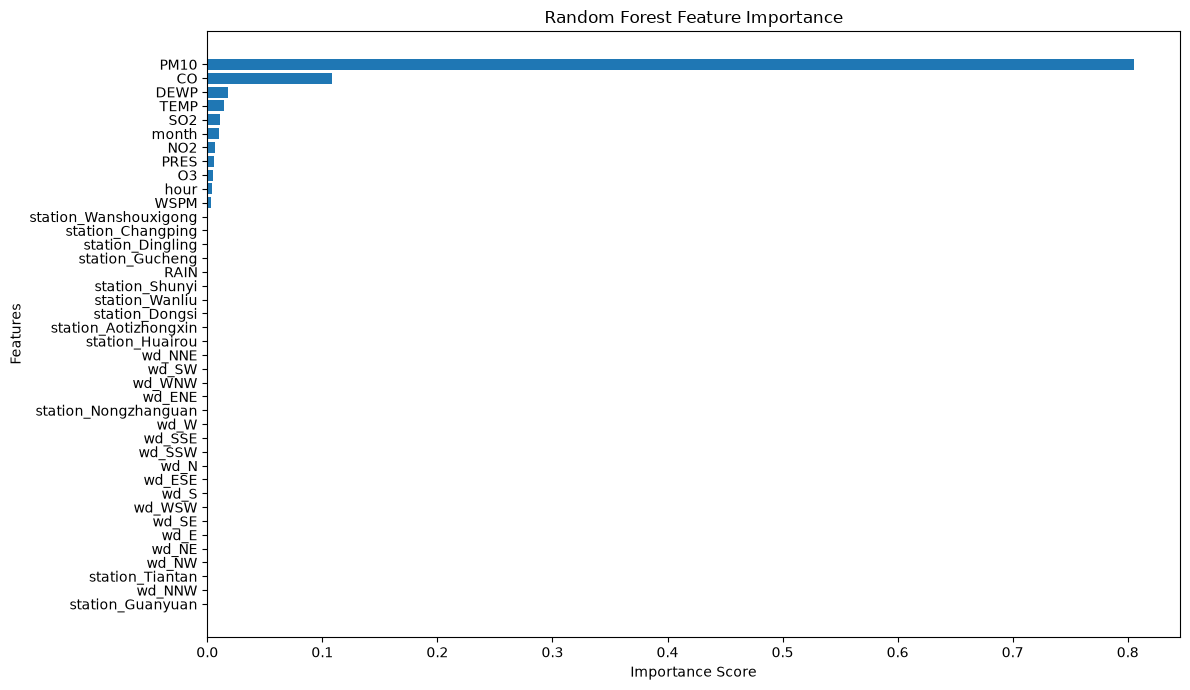

In [34]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print("Random Forest Feature Importance")
print("--------------------------------")
print(feature_importance.round(4))

plt.figure(figsize=(12, 7))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [36]:
import joblib

joblib.dump(rf_model, "random_forest_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [37]:
model_data = {
    "model": rf_model,
    "feature_columns": list(X_train.columns)
}

joblib.dump(model_data, "air_quality_model.pkl")

print("Model and feature information saved successfully!")
print("Number of features:", len(model_data["feature_columns"]))

Model and feature information saved successfully!
Number of features: 40


In [38]:
joblib.dump(upper_threshold, "anomaly_threshold.pkl")
print("Anomaly detection threshold saved successfully!")

Anomaly detection threshold saved successfully!


In [39]:
print(os.listdir())

['.antigravity-ide', '.bash_history', '.cache', '.copilot', '.gemini', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.m2', '.packettracer', '.vscode', '.vscode-shared', 'air_quality_model.pkl', 'Air_Quality_Prediction.ipynb', 'anomaly_threshold.pkl', 'AppData', 'Application Data', 'average_email_length.png', 'Cisco Packet Tracer 9.0.0', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'email_body_length_boxplot.png', 'email_body_length_boxplot_zoomed.png', 'Favorites', 'ham_spam_distribution.png', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'ml_env', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf.cnpf', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000001.regtrans

In [41]:
!python -m pip install streamlit

     ---------------------------------------- 0.0/62.1 kB ? eta -:--:--
     ------------------ ------------------- 30.7/62.1 kB 640.0 kB/s eta 0:00:01
     ------------------ ------------------- 30.7/62.1 kB 640.0 kB/s eta 0:00:01
     -------------------------------------  61.4/62.1 kB 409.6 kB/s eta 0:00:01
     -------------------------------------- 62.1/62.1 kB 367.7 kB/s eta 0:00:00
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.1/11.2 MB 1.1 MB/s eta 0:00:11
   ---------------------------------------- 0.1/11.2 MB 871.5 kB/s eta 0:00:13
    --------------------------------------- 0.1/11.2 MB 853.3 kB/s eta 0:00:13
    --------------------------------------- 0.2/11.2 MB 833.5 kB/s eta 0:00:14
    --------------------------------------- 0.2/11.2 MB 700.2 kB/s eta 0:00:16
    --------------------------------------- 0.2/11.2 MB 655.1 kB/s eta 0:00


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
%%writefile app.py
import streamlit as st

st.set_page_config(
    page_title="Air Quality Prediction",
    page_icon="🌍",
    layout="wide"
)
st.title("🌍 Air Quality Prediction System")
st.write("Predict PM2.5 concentration and identify high-pollution anomalies.")

st.success("Streamlit application is running!")

Writing app.py


In [46]:
model_data = joblib.load("air_quality_model.pkl")

loaded_model = model_data["model"]
feature_columns = model_data["feature_columns"]

print("Model loaded successfully!")
print("Expected input features:", len(feature_columns))

Model loaded successfully!
Expected input features: 40


In [47]:
print(feature_columns)

['PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'month', 'hour', 'wd_E', 'wd_ENE', 'wd_ESE', 'wd_N', 'wd_NE', 'wd_NNE', 'wd_NNW', 'wd_NW', 'wd_S', 'wd_SE', 'wd_SSE', 'wd_SSW', 'wd_SW', 'wd_W', 'wd_WNW', 'wd_WSW', 'station_Aotizhongxin', 'station_Changping', 'station_Dingling', 'station_Dongsi', 'station_Guanyuan', 'station_Gucheng', 'station_Huairou', 'station_Nongzhanguan', 'station_Shunyi', 'station_Tiantan', 'station_Wanliu', 'station_Wanshouxigong']


In [52]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

model_data = joblib.load("air_quality_model.pkl")
model = model_data["model"]
feature_columns = model_data["feature_columns"]
anomaly_threshold = joblib.load("anomaly_threshold.pkl")

st.set_page_config(
    page_title="Air Quality Prediction System",
    page_icon="🌍",
    layout="wide"
)

st.title("🌍 Air Quality Prediction System")
st.write("Estimate PM2.5 concentration and identify unusually high pollution readings.")
st.info(
    "Enter environmental measurements to estimate PM2.5 concentration and assess pollution levels."
)

wind_directions = ["E", "ENE", "ESE", "N", "NE", "NNE", "NNW", "NW", "S", "SE", "SSE", "SSW", "SW", "W", "WNW", "WSW"]
stations = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", 
            "Huairou", "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]

tab1, tab2 = st.tabs([
    "PM2.5 Prediction",
    "Pollution Anomaly Detection"
])

with tab1:
    st.header("Predict PM2.5 Concentration")
    st.write("Enter the pollutant and weather measurements below.")

    with st.form("prediction_form"):
        st.subheader("Pollutant Measurements")
        col1, col2, col3 = st.columns(3)

        with col1:
            pm10 = st.number_input("PM10 (µg/m³)", min_value=0.0, value=100.0)
            so2 = st.number_input("SO2 (µg/m³)", min_value=0.0, value=10.0)
        with col2:
            no2 = st.number_input("NO2 (µg/m³)", min_value=0.0, value=40.0)
            co = st.number_input("CO (mg/m³)", min_value=0.0, value=1.0)
        with col3:
            o3 = st.number_input("O3 (µg/m³)", min_value=0.0, value=60.0)

        st.subheader("Weather Measurements")
        col1, col2, col3 = st.columns(3)

        with col1:
            temp = st.number_input("Temperature (°C)", value=15.0)
            pres = st.number_input("Pressure (hPa)", value=1010.0)
        with col2:
            dewp = st.number_input("Dew Point (°C)", value=5.0)
            rain = st.number_input("Rainfall (mm)", min_value=0.0, value=0.0)
        with col3:
            wspm = st.number_input("Wind Speed (m/s)", min_value=0.0, value=1.0)
            wd = st.selectbox("Wind Direction", wind_directions)

        st.subheader("Time and Monitoring Station")
        col1, col2, col3 = st.columns(3)

        with col1:
            month = st.selectbox("Month", list(range(1, 13)), index=0)
        with col2:
            hour = st.selectbox("Hour", list(range(24)), index=12)
        with col3:
            station = st.selectbox("Monitoring Station", stations)

        predict_button = st.form_submit_button("Predict PM2.5", type="primary")

    if predict_button:
        input_data = pd.DataFrame(
            0,
            index=[0],
            columns=feature_columns
        )

        input_values = {
            "PM10": pm10,
            "SO2": so2,
            "NO2": no2,
            "CO": co,
            "O3": o3,
            "TEMP": temp,
            "PRES": pres,
            "DEWP": dewp,
            "RAIN": rain,
            "WSPM": wspm,
            "month": month,
            "hour": hour
        }

        for feature, value in input_values.items():
            input_data.at[0, feature] = value

        wind_column = "wd_" + wd
        station_column = "station_" + station

        if wind_column in input_data.columns:
            input_data.at[0, wind_column] = 1

        if station_column in input_data.columns:
            input_data.at[0, station_column] = 1

        prediction = model.predict(input_data)[0]

        st.success("PM2.5 prediction completed!")

        st.metric(
            label="Predicted PM2.5 Concentration",
            value=f"{prediction:.2f} µg/m³"
        )
        st.caption(
            "This is an estimate based on the values you entered, "
            "not a live air-quality measurement."
        )

with tab2:

    st.header("Pollution Anomaly Detection")
    st.write(
        "You can enter a PM2.5 reading to check whether it exceeds the statistical high-pollution threshold identified using the IQR method."
    )

    pm25_value = st.number_input(
        "Enter PM2.5 Reading (µg/m³)",
        min_value=0.0,
        value=100.0,
        key="anomaly_input"
    )

    if st.button("Check Pollution Level", type="primary"):
        if pm25_value > anomaly_threshold:
            st.error(
                "High-pollution anomaly detected! "
                "This reading is unusually high compared with the dataset distribution."
            )
        else:
            st.success(
                "No high-pollution anomaly detected according to the IQR threshold."
            )

        st.write(f"Entered PM2.5 reading: **{pm25_value:.2f} µg/m³**")

Overwriting app.py


In [54]:
import os
import shutil
import sklearn
import streamlit
import joblib

app_folder = os.path.join(os.getcwd(), "Air_Quality_App")
os.makedirs(app_folder, exist_ok=True)

files = [
    "app.py",
    "air_quality_model.pkl",
    "anomaly_threshold.pkl"
]

for file in files:
    shutil.copy2(file, app_folder)

requirements = f"""streamlit=={streamlit.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""

with open(os.path.join(app_folder, "requirements.txt"), "w") as f:
    f.write(requirements)

print("Deployment folder created successfully!")
print(os.listdir(app_folder))

Deployment folder created successfully!
['air_quality_model.pkl', 'anomaly_threshold.pkl', 'app.py', 'requirements.txt']


In [55]:
import os

for file in os.listdir(app_folder):
    size = os.path.getsize(os.path.join(app_folder, file)) / (1024 * 1024)
    print(f"{file}: {size:.2f} MB")

air_quality_model.pkl: 94.53 MB
anomaly_threshold.pkl: 0.00 MB
app.py: 0.00 MB
requirements.txt: 0.00 MB


In [56]:
import joblib
import os

compressed_path = os.path.join(app_folder, "air_quality_model.pkl")

joblib.dump(model_data, compressed_path, compress=3)

size = os.path.getsize(compressed_path) / (1024 * 1024)

print(f"Compressed model size: {size:.2f} MB")

Compressed model size: 23.56 MB
